**MAGALY BENAVIDES SANTIAGO**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OBJETIVO: ORGANIZAR INFORMACIÓN EN VARIBLES QUE UN MODELOS PUEDA USAR PARA PREDECIR

In [2]:
ruta_processed = Path("data/processed")
archivo_volatility = (ruta_processed /"SPY_2015_2025_volatility.csv")
archivo_features = (ruta_processed /"SPY_2015_2025_features.csv")

In [3]:
if not archivo_volatility.exists():
    raise FileNotFoundError(f"No se encontro el archivo: {archivo_volatility}")

In [4]:
datos_vol = pd.read_csv(archivo_volatility, index_col=0,parse_dates=True) 
datos = datos_vol.copy(deep=True)

In [5]:
print(datos.shape)
print(datos.index.min())
print(datos.index.max())
print(datos.columns.tolist())
datos.head()

(2765, 13)
2015-01-05 00:00:00
2025-12-31 00:00:00
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Return', 'Abs_Return', 'Sq_Return', 'Vol_5', 'Vol_10', 'Vol_20', 'Vol_30']


,Open,High,Low,Close,Adj Close,Volume,Return,Abs_Return,Sq_Return,Vol_5,Vol_10,Vol_20,Vol_30
Date,,,,,,,,,,,,,
2015-01-05,204.169998,204.369995,201.350006,201.720001,166.623337,169632600,-0.018225,0.018225,0.000332,NaN,NaN,NaN,NaN
2015-01-06,202.089996,202.720001,198.860001,199.820007,165.053909,209151400,-0.009464,0.009464,0.000090,NaN,NaN,NaN,NaN
2015-01-07,201.419998,202.720001,200.880005,202.309998,167.110703,125346700,0.012384,0.012384,0.000153,NaN,NaN,NaN,NaN
2015-01-08,204.009995,206.160004,203.990005,205.899994,170.076080,147217800,0.017589,0.017589,0.000309,NaN,NaN,NaN,NaN
2015-01-09,206.399994,206.419998,203.509995,204.250000,168.713120,158567300,-0.008046,0.008046,0.000065,0.015351,NaN,NaN,NaN


VERIFICAMOS QUE EXISTAN LAS COLUMNAS NECESARIAS, QUE EL INDICE ESTE ORDENADO Y SIN DUPLICADOS, Y QUE RETURN/ABS_RETURN/SQ_RETURN NO TENGA NaN, RECORDANDO QUE LAS VOLATILIDADES SI TIENEN NAN INCIALES. 

In [6]:
columnas_necesarias = ["Open","High", "Low","Close","Adj Close","Volume"
,"Return","Abs_Return","Sq_Return","Vol_5","Vol_10","Vol_20","Vol_30"]

faltantes = [col for col in columnas_necesarias if col not in datos.columns]
assert len(faltantes) == 0, (f"Faltan columnas: {faltantes}")

In [7]:
#REVISAMOS EL ORDEN TEMPORAL
assert datos.index.is_monotonic_increasing
assert datos.index.is_unique

In [8]:
#REVISAMOS LA INTEGRIDAD DE LOS RENDIMIENTOS
assert not datos["Return"].isna().any()
assert not datos["Abs_Return"].isna().any()
assert not datos["Sq_Return"].isna().any()
assert np.isfinite(datos["Return"]).all()

1. Construya los rezagos 1, 2, 5 y 10 de Return, Abs_Return y Sq_Return. Seleccione una
fecha intermedia y verifique manualmente al menos dos de los valores obtenidos.

In [9]:
#OBTENEMOS LOS REZAGOS DE LOS RENDIMIENTOS
lags = [1, 2, 5, 10]
for lag in lags:
    datos[f"Return_Lag_{lag}"] = ( datos["Return"].shift(lag))
for lag in lags:
    datos[f"Abs_Return_Lag_{lag}"] = ( datos["Abs_Return"].shift(lag))
for lag in lags:
    datos[f"Sq_Return_Lag_{lag}"] = ( datos["Sq_Return"].shift(lag))

In [10]:
#REZAGO DE VOLATILIDAD HISTORICA
#SE TOMA CADA UNA DE LAS COLUMNAS QUE YA TENIAMOS Y SE LE APLICA UN REZAGO DE UN DIA.
ventanas_vol = [5, 10, 20, 30]
for w in ventanas_vol:
    datos[f"Vol_{w}_Lag_1"] = (datos[f"Vol_{w}"].shift(1))

MANERA MANUAL

In [11]:
#TOMAMOS LA FILA 15 DE RETURN_LAG_2  SE COMPARA CON LA FILA 149  RETURN
i = 150
actual=datos["Return_Lag_2"].iloc[i]
esperado = datos["Return"].iloc[i - 2]
print("Return_Lag_2", actual)
print("Return anterior:", esperado)
assert np.isclose(actual, esperado)
#LA INFROMACION DEBE COINCIDIR PORQUE POR DEFINICION RETURN _LAG_1 ES LA POSICION
# I DEBE SER IGUAL A RETURN EN LA POSICION I-1

Return_Lag_2 -0.0082214233756259
Return anterior: -0.0082214233756259


In [12]:
actual = datos["Return_Lag_5"].iloc[i]
esperado = datos["Return"].iloc[i - 5]
print("Return_Lag_5:", actual)
print("Return anterior:", esperado)
assert np.isclose(actual, esperado)

Return_Lag_5: -0.0033784301390111
Return anterior: -0.0033784301390111


UN REZAGO DE ORDEN K GENERA EXACTAMENTE K VALORES FALTANTES AL INICIO(NO COMO K-1 COMO EN LAS VENTANA MOVILES), EL REZAGO NO ACUMULA OBSERVACIONES SINO DESPLAZA 

In [13]:
for lag in lags:variable = f"Return_Lag_{lag}"
print(variable, datos[variable].isna().sum())

Return_Lag_10 10


In [14]:
for lag in lags:
    variable = f"Return_Lag_{lag}"
assert (datos[variable].isna().sum()== lag)

2. Construya las medias móviles de 5, 10 y 20 días de Return y Abs_Return. Compare
Mean_Abs_Return_20 con Vol_20 y explique por qué las dos medidas no son iguales.

In [15]:
ventanas_ma = [5, 10, 20]

for w in ventanas_ma:
    datos[f"Mean_Return_{w}"] = (datos["Return"].rolling(window=w).mean())
for w in ventanas_ma:
    datos[f"Mean_Abs_Return_{w}"] = (datos["Abs_Return"].rolling(window=w).mean())

NOTAMOS QUE YA TENIA 99 NAN POR SER VENTANA MOVIL Y AL APLICARLE SHIFT(1) PARA CREAR VOL_30_LAG_1 SE LE SUMA UN NAN ADICIONAL AL REZAGO OBTENIENDO 30 NANA EN TOTAL, ESTO ES ¨VENTANA + DESPLAZAMIENTO¨

In [16]:
#CALCULA EL PROMEDIO SIMPLE DE LOS ULTIMOS W RENDIMIENTOS
w = 20
i = 100
ventana_manual = (datos["Return"].iloc[i-w+1:i+1])
media_manual = ventana_manual.mean()
media_python = datos["Mean_Return_20"].iloc[i]
print("Manual:", media_manual)
print("Rolling:", media_python)
assert len(ventana_manual) == w
assert np.isclose(media_manual,media_python)
#COMPARAMOS LA PARTE MANUAL Y LA QUE DA PANDAS, DE LAS VENTANAS MOVILES USANDO
#EL PROMEDIO SIMPLE DE LOS RENDIMIENTOS 

Manual: 0.0006387093850243198
Rolling: 0.0006387093850243203


In [17]:
#USAMOS ROLLING().MEAN() EN ABS_RETURN (SIMPRE POSITIVO, MIDE EL TAMAÑO DEL MOVIMIENTO)
for w in ventanas_ma:
    datos[f"Mean_Abs_Return_{w}"] = (datos["Abs_Return"].rolling(window=w).mean())

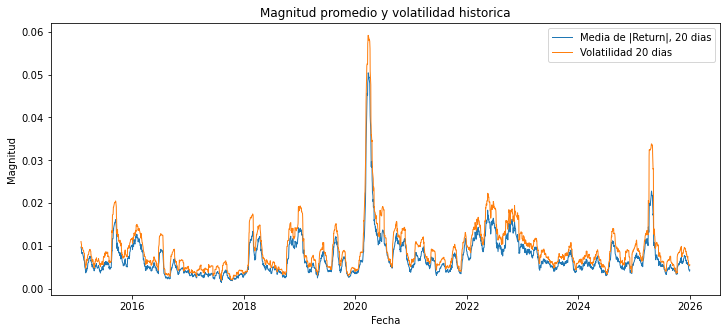

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(datos.index, datos["Mean_Abs_Return_20"],label="Media de |Return|, 20 dias",linewidth=1)
ax.plot(datos.index, datos["Vol_20"], label="Volatilidad 20 dias", linewidth=1)
ax.set_title("Magnitud promedio y volatilidad historica")
ax.set_xlabel("Fecha")
ax.set_ylabel("Magnitud")
ax.legend()
plt.show()
#GRAFICA MAGNITUD DE PROMEDIO DE MOVIMIENTOS Y VOLATILIDAD(DISPERSION) 

NOTAMOS QUE LAS LINEAS VAN CASI PEGADAS AL INICIO, PORQUE MIDEN QUÉ TAN MOVIDO HA ESTADO EL MERCADO USANDO DESVIACION ESTANDAR Y EL PROMEDIO DE VALOR ABSOLUTO DÍA A DÍA, AUNQUE EN EL 2020 TRAS EL COVID, LA LINEA NARANJA SUBE MAS ALTO Y ESO ES DEBIDO QUE LA DESVIACION ESTANDAR ES MAS SENSIBLE A LA VARIABILIDAD ENTRE LOS DIAS NO SOLO A SU TAMAÑO PROMEDIO

3. Calcule Momentum_5 y Momentum_20. Identifique las cinco fechas con mayor y las cinco fechas
con menor Momentum_20. Interprete el signo del indicador.

In [19]:
#USAMOS LA FORMULA DEL RENDIMIENTO LOGARITMICO SIMPLE 
datos["Momentum_5"] = np.log(datos["Adj Close"] / datos["Adj Close"].shift(5) )
datos["Momentum_20"] = np.log(datos["Adj Close"] /datos["Adj Close"].shift(20))

In [20]:
mayor_5= datos[["Adj Close", "Momentum_20"]].dropna().nlargest(5, "Momentum_20")
menor_5= datos[["Adj Close", "Momentum_20"]].dropna().nsmallest(5, "Momentum_20")
print('Mayor Momentum_20', mayor_5)
print('Menor Momentum_20', menor_5)

Mayor Momentum_20              Adj Close  Momentum_20
Date                               
2020-04-20  258.184052     0.207604
2020-04-21  250.344757     0.202671
2020-04-17  262.814270     0.181328
2020-04-14  260.201202     0.174084
2020-04-30  266.335175     0.165594
Menor Momentum_20              Adj Close  Momentum_20
Date                               
2020-03-20  209.781982    -0.370872
2020-03-23  204.418259    -0.363044
2020-03-18  218.764633    -0.343412
2020-03-16  218.627914    -0.341848
2020-03-19  219.229492    -0.337173


Un momentum_20 positivo indica que el precio subio con fuerza en los ultimos 20 dias
Un momentum_20 muy negativo indica una caida fuerte en ese peridod

In [21]:
#RECONSTRUIMOS EL CALCULO A MANO Y CON PYTHON
i = 100
momentum_manual = np.log(datos["Adj Close"].iloc[i] /datos["Adj Close"].iloc[i - 20])
momentum_python = (datos["Momentum_20"].iloc[i])
print("Manual:", momentum_manual)
print("Python:", momentum_python)
assert np.isclose(momentum_manual,momentum_python)

Manual: 0.012774187700487123
Python: 0.012774187700487123


4. Construya Volume_Change y Range_HL. Obtenga estadísticas descriptivas de ambas variables.
Determine si las fechas con mayor rango intradiario tienden a coincidir con periodos de
elevada Vol_20.

In [22]:
#CALCULAR AUTOMATICAMENTE EL VALOR DE (HOY/VALOR DE AYER) -1, EL CAMBIO PORCENTUAL RESPECTO AL DIA ANTERIOR
datos["Volume_Change"] = (datos["Volume"].pct_change(fill_method=None))

In [23]:
#MIDE QUÉ TAN ANCHO FUE EL RANGO DE PRECIOS DEL DIA (MAXIMO-MINIMO) NORMALIZADO POR EL PRECIO DE CIERRE
datos["Range_HL"] = ((datos["High"] - datos["Low"]) / datos["Close"])

In [24]:
resumen= datos[['Volume_Change', 'Range_HL']].describe().T
resumen

,count,mean,std,min,25%,50%,75%,max
Volume_Change,2764.0,0.051886,0.354092,-0.687575,-0.187578,-0.005082,0.224865,2.360032
Range_HL,2765.0,0.011315,0.008824,0.001229,0.005964,0.008843,0.013665,0.101291


In [25]:
range_10= datos[["Range_HL", "Vol_20"]].dropna().nlargest(10, "Range_HL")
vol20_10= datos[["Range_HL", "Vol_20"]].dropna().nlargest(10, "Vol_20")
coincidencias= range_10.index.intersection(vol20_10.index)
print('Fechas que coinciden', len(coincidencias))
print(coincidencias)

Fechas que coinciden 1
DatetimeIndex(['2020-04-06'], dtype='datetime64[ns]', name='Date', freq=None)


Solo 1 de cada 10 fechas coinciden exactamente, sin embargo no significa que no haya relacion, range_hl es una medida diaria mientras que vol_20 resume un periodo de 20 dias que cambia lentamente 

In [26]:
#SIEMPRE ES MAYOR/IGUAL A CERO
assert (datos["High"] >= datos["Low"]).all()
assert (datos["Close"] > 0).all()
assert (datos["Range_HL"] >= 0).all()

5. Construya Ratio_Vol_5_30. Calcule qué proporción de observaciones válidas satisface
Ratio_Vol_5_30 > 1.
Identifique algunos periodos en los cuales el cociente alcance valores particularmente altos.

In [27]:
#SI EL VOL_30 ES MAYOR A CERO, CALCULA LA DIVISION SINO PON NAN EN SU LUGAR, EVITAMOS DIVISIONES ENTRE CERO
datos["Ratio_Vol_5_30"] = np.where(datos["Vol_30"] > 0, datos["Vol_5"] / datos["Vol_30"], np.nan)

In [28]:
valores_validos= datos['Ratio_Vol_5_30'].dropna()
proporcion_mayor_1= (valores_validos > 1).mean()
print(f'proporcion con Ratio_Vol_5_10 > 1: {proporcion_mayor_1:.2%}')

proporcion con Ratio_Vol_5_10 > 1: 36.00%


In [29]:
ratio_alto= datos[['Vol_5', 'Vol_30', 'Ratio_Vol_5_30']].dropna().nlargest(10, 'Ratio_Vol_5_30' )
ratio_alto


,Vol_5,Vol_30,Ratio_Vol_5_30
Date,,,
2018-10-16,0.022911,0.009329,2.455719
2016-06-29,0.024629,0.010190,2.417075
2025-04-09,0.063747,0.026486,2.406826
2015-08-27,0.034759,0.014504,2.396455
2016-09-15,0.016234,0.006808,2.384552
2016-06-30,0.024720,0.010466,2.361980
2016-09-12,0.014024,0.006120,2.291653
2025-04-10,0.062785,0.027491,2.283814
2016-06-28,0.022494,0.009853,2.282969


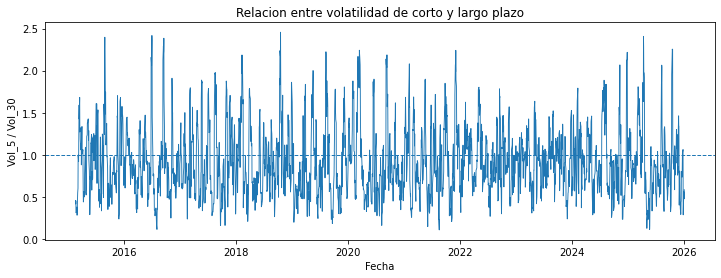

In [30]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot( datos.index, datos["Ratio_Vol_5_30"],linewidth=0.9)
ax.axhline(1,linestyle="--",linewidth=1)
ax.set_title("Relacion entre volatilidad de corto y largo plazo")
ax.set_xlabel("Fecha")
ax.set_ylabel("Vol_5 / Vol_30") 
plt.show()

OBSERVAMOS QUE HAY UNA LINEA HORIZONTAL EN 1 PARA VER CUANDO EL COCIENTE CRUZA, ES DECIR, ARRIBA: EL CORTO PLAZO ES MAS VOLATIL, ABAJO ES TODO LO CONTRARIO  
el 36% de los dias muestra que Ratio_Vol_5_30 > 1 nos indica que el mercado pasa un porcion considerable del tiempo con la volatilidad reciente por encima de su nivel de referencia de largo plazo. 

In [31]:
#COMPARAMOS LAS COLUMNAS ACTUALES CON LAS ANTERIORES, QUEDANDOSE CON LAS GENERADAS 
columnas_nuevas = [col for col in datos.columns if col not in datos_vol.columns]
print("Numero de variables nuevas:")
print(len(columnas_nuevas))
print("\nVariables nuevas:")
print(columnas_nuevas)

Numero de variables nuevas:
27

Variables nuevas:
['Return_Lag_1', 'Return_Lag_2', 'Return_Lag_5', 'Return_Lag_10', 'Abs_Return_Lag_1', 'Abs_Return_Lag_2', 'Abs_Return_Lag_5', 'Abs_Return_Lag_10', 'Sq_Return_Lag_1', 'Sq_Return_Lag_2', 'Sq_Return_Lag_5', 'Sq_Return_Lag_10', 'Vol_5_Lag_1', 'Vol_10_Lag_1', 'Vol_20_Lag_1', 'Vol_30_Lag_1', 'Mean_Return_5', 'Mean_Return_10', 'Mean_Return_20', 'Mean_Abs_Return_5', 'Mean_Abs_Return_10', 'Mean_Abs_Return_20', 'Momentum_5', 'Momentum_20', 'Volume_Change', 'Range_HL', 'Ratio_Vol_5_30']


In [32]:
datos[["Return","Return_Lag_1", "Return_Lag_5", "Mean_Return_5", "Mean_Abs_Return_20", "Vol_20",
 "Vol_20_Lag_1", "Momentum_20", "Volume_Change", "Range_HL","Ratio_Vol_5_30" ]].head(35)

,Return,Return_Lag_1,Return_Lag_5,Mean_Return_5,Mean_Abs_Return_20,Vol_20,Vol_20_Lag_1,Momentum_20,Volume_Change,Range_HL,Ratio_Vol_5_30
Date,,,,,,,,,,,
2015-01-05,-0.018225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.014971,NaN
2015-01-06,-0.009464,-0.018225,NaN,NaN,NaN,NaN,NaN,NaN,0.232967,0.019317,NaN
2015-01-07,0.012384,-0.009464,NaN,NaN,NaN,NaN,NaN,NaN,-0.400689,0.009095,NaN
2015-01-08,0.017589,0.012384,NaN,NaN,NaN,NaN,NaN,NaN,0.174485,0.010539,NaN
2015-01-09,-0.008046,0.017589,NaN,-0.001152,NaN,NaN,NaN,NaN,0.077093,0.014247,NaN
2015-01-12,-0.007864,-0.008046,-0.018225,0.000920,NaN,NaN,NaN,NaN,-0.089370,0.013225,NaN
2015-01-13,-0.002817,-0.007864,-0.009464,0.002249,NaN,NaN,NaN,NaN,0.485866,0.024594,NaN
2015-01-14,-0.006055,-0.002817,0.012384,-0.001439,NaN,NaN,NaN,NaN,-0.100498,0.012596,NaN
2015-01-15,-0.009203,-0.006055,0.017589,-0.006797,NaN,NaN,NaN,NaN,-0.084860,0.015727,NaN


4. Explique con sus propias palabras por qué una variable construida mediante shift(1) puede
utilizarse como predictor, mientras que una variable construida mediante shift(-1) no
debe utilizarse como variable explicativa.

Recordando qur shift(1) trae el valor de una fila atras en la fecha t coloca lo que paso en t-1 y shif(-1) trae un valor de una fila adelante en la fecha t y lo coloca en t+1.   
Recordando lo que hemos visto anteriomente, una variable predictora asociada a la fecha t puede dependeer de infromacion correspondiente a t o a fechas anteriores, pero nunca de observaciones posteriores a t y shift(-1), no lo respeta, porque desplza la serie hacia el futuro, un dato que en ese momento no existe. 

## ESTADISTICAS DESCRIPTIVA

In [33]:
#La tabla permite revisar magnitudes, posibles valores extremos y diferencias de escala entre predictores.
variables_resumen = ["Return_Lag_1", "Return_Lag_5","Mean_Return_5","Mean_Return_20",
 "Mean_Abs_Return_20", "Momentum_5", "Momentum_20", "Volume_Change","Range_HL","Ratio_Vol_5_30"]
resumen = (datos[variables_resumen] .describe().T )
resumen

,count,mean,std,min,25%,50%,75%,max
Return_Lag_1,2764.0,0.000504,0.011233,-0.115887,-0.003705,0.000645,0.005909,0.099863
Return_Lag_5,2760.0,0.000505,0.011241,-0.115887,-0.003712,0.000653,0.005913,0.099863
Mean_Return_5,2761.0,0.000509,0.004626,-0.039615,-0.001383,0.000915,0.002941,0.032012
Mean_Return_20,2746.0,0.000510,0.002233,-0.018544,-0.000390,0.000840,0.001736,0.010380
Mean_Abs_Return_20,2746.0,0.007318,0.004987,0.001497,0.004434,0.005956,0.009090,0.050426
Momentum_5,2760.0,0.002548,0.023132,-0.198077,-0.006921,0.004574,0.014707,0.160060
Momentum_20,2745.0,0.010212,0.044675,-0.370872,-0.007772,0.016810,0.034759,0.207604
Volume_Change,2764.0,0.051886,0.354092,-0.687575,-0.187578,-0.005082,0.224865,2.360032
Range_HL,2765.0,0.011315,0.008824,0.001229,0.005964,0.008843,0.013665,0.101291
Ratio_Vol_5_30,2736.0,0.927908,0.417166,0.108850,0.624752,0.861976,1.166861,2.455719


In [34]:
#VARIABLES DE CORRELACION DE PEARSON: CUANDO ES IGUAL A 1 NOS DICE QUE SI UNA VARIABLE AUMNETA LA OTRA AUMENTA DE FROMA CONSTANTE
variables_corr = [ "Return", "Return_Lag_1", "Return_Lag_5",
"Abs_Return","Mean_Abs_Return_20","Vol_5",
"Vol_20", "Vol_30", "Momentum_20", "Range_HL", "Ratio_Vol_5_30"]
correlaciones = (datos[variables_corr].corr())
correlaciones
# QUE TANTO SE PARECEN MIS NUEVAS VARIABLES ENTRE SÍ

,Return,Return_Lag_1,Return_Lag_5,Abs_Return,Mean_Abs_Return_20,Vol_5,Vol_20,Vol_30,Momentum_20,Range_HL,Ratio_Vol_5_30
Return,1.000000,-0.119096,0.039920,-0.094870,0.016660,-0.024599,0.010069,0.018786,0.220654,-0.155056,-0.028160
Return_Lag_1,-0.119096,1.000000,-0.063805,-0.114368,0.003668,-0.069379,-0.006245,0.010716,0.193985,-0.191751,-0.082718
Return_Lag_5,0.039920,-0.063805,1.000000,-0.075420,-0.053302,-0.181390,-0.060297,-0.028398,0.204035,-0.126396,-0.174074
Abs_Return,-0.094870,-0.114368,-0.075420,1.000000,0.519536,0.679924,0.529260,0.474447,-0.415095,0.718551,0.386232
Mean_Abs_Return_20,0.016660,0.003668,-0.053302,0.519536,1.000000,0.768285,0.987848,0.942799,-0.424977,0.628688,0.063182
Vol_5,-0.024599,-0.069379,-0.181390,0.679924,0.768285,1.000000,0.785143,0.706099,-0.563301,0.753997,0.563547
Vol_20,0.010069,-0.006245,-0.060297,0.529260,0.987848,0.785143,1.000000,0.943681,-0.438896,0.643524,0.089806
Vol_30,0.018786,0.010716,-0.028398,0.474447,0.942799,0.706099,0.943681,1.000000,-0.254986,0.581807,-0.028047
Momentum_20,0.220654,0.193985,0.204035,-0.415095,-0.424977,-0.563301,-0.438896,-0.254986,1.000000,-0.553658,-0.378245
Range_HL,-0.155056,-0.191751,-0.126396,0.718551,0.628688,0.753997,0.643524,0.581807,-0.553658,1.000000,0.365017


In [35]:
# CUENTA LOS FALTANTES Y LOS ORDENA DE MAYOR A MENOR NANS 
nan_por_columna = ( datos.isna().sum().sort_values(ascending=False))
nan_por_columna.head(20)

Vol_30_Lag_1          30
Ratio_Vol_5_30        29
Vol_30                29
Momentum_20           20
Vol_20_Lag_1          20
Vol_20                19
Mean_Abs_Return_20    19
Mean_Return_20        19
Vol_10_Lag_1          10
Sq_Return_Lag_10      10
Return_Lag_10         10
Abs_Return_Lag_10     10
Vol_10                 9
Mean_Abs_Return_10     9
Mean_Return_10         9
Return_Lag_5           5
Momentum_5             5
Vol_5_Lag_1            5
Abs_Return_Lag_5       5
Sq_Return_Lag_5        5
dtype: int64

In [36]:
# VERIFICA QUE LOS REZAGOS SEAN CORRECTOS DENTRO DE UNFOR QUE RECORRE LOS 4 LAGS
i = 100
for lag in lags:
    esperado = datos["Return"].iloc[i - lag]
    obtenido = datos[f"Return_Lag_{lag}"].iloc[i]
assert np.isclose(esperado, obtenido)

In [37]:
#RANGO INTRADIARIO SE DEBE CUMPLIR QUE LOS NAN NO DEBEN TENER INFINITOS
valores = datos["Range_HL"].dropna()
assert (valores >= 0).all()
assert np.isfinite(valores).all()

In [38]:
#REALIZAMOS UNA COPIA FINAL  DE MANERA INDEPENDIENTE  LISTA PARA EXPORTAR
datos_features = datos.copy()

In [39]:
#VERIFICAMOS QUE LA BSSE CONSERVE EL MISMO NUMERO DE FILAS QUE LA BASE DE ENTRADA
assert (datos_features.shape[0]== datos_vol.shape[0])
assert (datos_features.index.equals(datos_vol.index))
#VERIFICAMOS EL INDICE DE FECHAS, PARA QUE SE IDENTICO FECHA POR FECHA Y NO SOLO TENGA 
#LA MISMA CONTIDAD, ESO DESCARTA EL SEGUNDO ASSERT

## EXPORTACION

In [40]:
#ALMACENAMOS LA BASE E INDEXAMOS LA COLUMNA DE LAS FECHAS, PARA LA REFENCIA TEMPORAL
datos_features.to_csv(archivo_features,index=True)

In [41]:
verificacion = pd.read_csv(archivo_features,index_col=0,parse_dates=True )

In [42]:
# VERIFICAMOS DIMENSIONES, ORDEN TEMPORAL Y UNICIDAD, COMO SI LO LEYERA OTRA PERSONA
assert (verificacion.shape== datos_features.shape)
assert (verificacion.index.is_monotonic_increasing)
assert verificacion.index.is_unique

In [43]:
columnas_clave = ["Return_Lag_1", "Return_Lag_10", "Vol_20_Lag_1", "Mean_Return_20",
 "Mean_Abs_Return_20","Momentum_20", "Volume_Change","Range_HL", "Ratio_Vol_5_30" ]
for col in columnas_clave:
    assert col in verificacion.columns
# REVISAMOS UNA MUESTRA PARA CONFIRMAR QUE SOBREVIVIERON A LA EXPORTACION